## __Filtering and Trimming Messages__


### _Goals_
- Build a chatbot with long-term memory
- Since chatbot uses messages,first understand trimming messages in langgraph

In [51]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))
from typing import get_type_hints

from IPython.display import Image, display
from langchain_core.messages import (
    AIMessage,
    AnyMessage,
    BaseMessage,
    HumanMessage,
    RemoveMessage,
    trim_messages,
)
from langgraph.graph import END, START, MessagesState, StateGraph

from utils.model import Models


In [38]:
print(get_type_hints(MessagesState, include_extras=True))


{'messages': typing.Annotated[list[typing.Annotated[typing.Annotated[langchain_core.messages.ai.AIMessage, Tag(tag='ai')] | typing.Annotated[langchain_core.messages.human.HumanMessage, Tag(tag='human')] | typing.Annotated[langchain_core.messages.chat.ChatMessage, Tag(tag='chat')] | typing.Annotated[langchain_core.messages.system.SystemMessage, Tag(tag='system')] | typing.Annotated[langchain_core.messages.function.FunctionMessage, Tag(tag='function')] | typing.Annotated[langchain_core.messages.tool.ToolMessage, Tag(tag='tool')] | typing.Annotated[langchain_core.messages.ai.AIMessageChunk, Tag(tag='AIMessageChunk')] | typing.Annotated[langchain_core.messages.human.HumanMessageChunk, Tag(tag='HumanMessageChunk')] | typing.Annotated[langchain_core.messages.chat.ChatMessageChunk, Tag(tag='ChatMessageChunk')] | typing.Annotated[langchain_core.messages.system.SystemMessageChunk, Tag(tag='SystemMessageChunk')] | typing.Annotated[langchain_core.messages.function.FunctionMessageChunk, Tag(tag='F

In [2]:
model = Models()
llm = model.create_groq_model()


In [18]:
messages: list[AnyMessage] = [
    AIMessage("You said you were researching about ocean mammals", name="Bot")
]
messages.append(
    HumanMessage(
        "Yes I know about whales,But I want to know about more ocean mammals?",
        name="Jason",
    )
)
for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

You said you were researching about ocean mammals
================================ Human Message =================================
Name: Jason

Yes I know about whales,But I want to know about more ocean mammals?


In [4]:
response = llm.invoke(messages)

In [ ]:
print(response.content)

In [ ]:
response.response_metadata

In [9]:
def chat_model(state: MessagesState):
    return {"messages": llm.invoke(state["messages"])}

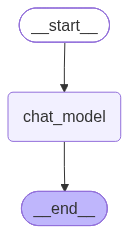

In [11]:
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
output = graph.invoke({"messages": messages})

### _Reducers_
- A practical challenge with messages is managing long-running conversations.
- Long-running conversations result in high token usage and latency if we are not careful,because we pass a growing list of messages to the model.
- Few ways to address this are 
  - `RemoveMessage`
  - `add_messages`

In [34]:
def chat_model_node(state: MessagesState):
    return {"messages": llm.invoke(state["messages"])}


def filter_messages(state: MessagesState):
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][10:-1]]
    return {"messages": delete_messages}

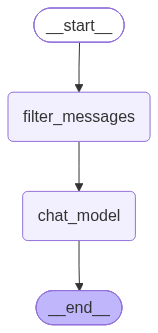

In [35]:
builder_1 = StateGraph(MessagesState)
builder_1.add_node("filter_messages", filter_messages)
builder_1.add_node("chat_model", chat_model_node)
builder_1.add_edge(START, "filter_messages")
builder_1.add_edge("filter_messages", "chat_model")
builder_1.add_edge("chat_model", END)
graph_1 = builder_1.compile()
display(Image(graph_1.get_graph().draw_mermaid_png()))

In [ ]:
output = graph_1.invoke({"messages": messages})
for m in output["messages"]:
    m.pretty_print()

#### _Trim Messages_

In [64]:
def chat_model_trim(state: MessagesState):
    messages = trim_messages(
        state["messages"],
        max_tokens=50,
        strategy="first",
        allow_partial=True,
        token_counter="approximate",
    )
    return {"messages": llm.invoke(messages)}

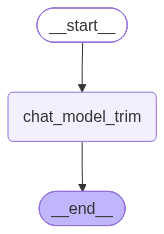

In [65]:
builder_2 = StateGraph(MessagesState)
builder_2.add_node("chat_model_trim", chat_model_trim)
builder_2.add_edge(START, "chat_model_trim")
builder_2.add_edge("chat_model_trim", END)
graph_2 = builder_2.compile()
display(Image(graph_2.get_graph().draw_mermaid_png()))

In [66]:
new_messages: list[BaseMessage] = [HumanMessage("Hi")]
new_messages.append(AIMessage("How can I help you"))
new_messages.append(HumanMessage("I am researching about blue whales"))

In [67]:
messages_trim_out = graph_2.invoke({"messages": new_messages})


In [68]:
messages_trim_out

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='9b3df399-4833-411f-97bc-6d07d823474d'),
  AIMessage(content='How can I help you', additional_kwargs={}, response_metadata={}, id='8d08f3cc-2c5e-4f35-bcc2-e5ceae52eb40', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='I am researching about blue whales', additional_kwargs={}, response_metadata={}, id='92f80ccd-3a32-400b-988e-986d4300c8f0'),
  AIMessage(content='## Blue Whale (Balaenoptera musculus) – A Quick‑Reference Overview  \n\n| **Category** | **Details** |\n|--------------|-------------|\n| **Common name** | Blue whale |\n| **Scientific name** | *Balaenoptera musculus* |\n| **Family** | Balaenopteridae (rorquals) |\n| **Order** | Cetacea |\n| **Conservation status** | **IUCN:** Endangered (EN) <br> **CITES:** Appendix\u202fI |\n| **Maximum recorded length** | 29.9\u202fm (98\u202fft) – female “Finland” (1998) |\n| **Maximum recorded weight** | 190\u202ft (≈\u202f210\u202fshort t